# A5 / E4 — Kontrol panjang teks — Anggota A
**Dikerjakan oleh:** [ito - mengambil alih]

**Versi:** V3.1_A2_PROVISIONAL (file yang sama dengan E3). **Split:** LATIH untuk fit, VALIDASI untuk evaluasi, UJI tetap terkunci.

**Pertanyaan:** berita VALID jauh lebih panjang daripada HOAKS (median ±302 vs 31 kata). Jika panjangnya disamakan, apakah model masih bisa membedakan keduanya?

**Desain singkat:**
1. Panjang target diambil dari distribusi jumlah kata teks HOAKS di LATIH (seed 42).
2. Teks VALID dipotong dari awal ke panjang target. Teks HOAKS tidak diubah. Hasilnya kolom `text_clean_e4`.
3. TF-IDF + ComplementNB (α = 0,1) dan LinearSVC (C = 1,0, balanced), sesuai keputusan kelompok K2 (hasil tuning B1 V3.1, 23 Nov).
4. Kondisi `normal` (teks utuh), `e4` (panjang disamakan), dan `silang` (latih utuh, nilai teks dipotong).
5. Cek desain: model yang hanya melihat jumlah kata harus turun mendekati 0,5 setelah E4.


Google Collab Ito: https://drive.google.com/file/d/1ZFq6eQ-2DzpcPERXCDEZ1Lo8IOlbDpvF/view?usp=sharing

In [1]:
%pip -q install numpy pandas scikit-learn matplotlib

## 1. Hubungkan Google Drive
Gunakan `DATASET_V3_1_KANDIDAT_OPERASIONAL.csv` yang sama dengan E3. Sel berikutnya membandingkan sidik file (SHA-256) dengan file yang dipakai E3.

In [2]:
from pathlib import Path
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Bukan Google Colab: gunakan lokasi CSV di perangkat ini.')

Mounted at /content/drive


In [3]:
import hashlib
DATASET_PATH = "/content/drive/MyDrive/Kelompok 5 - PSP/DATASET_V3_1_KANDIDAT_OPERASIONAL.csv"
assert Path(DATASET_PATH).is_file(), f"CSV tidak ditemukan. Ubah DATASET_PATH: {DATASET_PATH}"

SHA256_E3 = "a790c0a6175455f385529f98a48dbd5ee8d939805494168ad698bd56343bb295"   # dari results/anggota_a/E3_METADATA.json
h = hashlib.sha256()
with open(DATASET_PATH, "rb") as f:
    for block in iter(lambda: f.read(1 << 20), b""):
        h.update(block)
print("Dataset ditemukan:", DATASET_PATH)
print("SHA-256           :", h.hexdigest())
print("Sama dengan file E3:", h.hexdigest() == SHA256_E3)

Dataset ditemukan: /content/drive/MyDrive/Kelompok 5 - PSP/DATASET_V3_1_KANDIDAT_OPERASIONAL.csv
SHA-256           : a790c0a6175455f385529f98a48dbd5ee8d939805494168ad698bd56343bb295
Sama dengan file E3: True


### Cek isi data (dijalankan bila SHA-256 berbeda)
SHA-256 bisa berbeda walaupun isinya sama, misalnya karena file dibuat ulang, diunduh ulang, atau beda akhir baris. Sel ini mengulang dua angka E3 milik Anggota A dari kolom `text_clean_v31`. Jika keduanya identik, isi data LATIH dan VALIDASI sama dengan yang dipakai E3 dan E4 boleh dilanjutkan.

In [4]:
import re, numpy as np, pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

LETTER_WORD = re.compile(r"\b[^\W\d_]+\b", flags=re.UNICODE)
def style_features(text):                      # sama dengan a4_e3_style.py
    text = "" if pd.isna(text) else str(text)
    n_letters = sum(ch.isalpha() for ch in text); upper = sum(ch.isupper() for ch in text)
    words_alpha = LETTER_WORD.findall(text)
    return (upper / n_letters if n_letters else 0.0, text.count("!"), text.count("?"),
            sum(len(w) > 2 and w.isupper() for w in words_alpha), len(text.split()))

d3 = pd.read_csv(DATASET_PATH, usecols=["raw_id", "label", "random_split", "text_clean_v31"], encoding="utf-8-sig")
d3 = d3.loc[d3.random_split.isin(["LATIH", "VALIDASI"])]
X3 = np.asarray([style_features(t) for t in d3.text_clean_v31.fillna("")], dtype=float); y3 = d3.label.to_numpy()
mt, mv = d3.random_split.eq("LATIH").to_numpy(), d3.random_split.eq("VALIDASI").to_numpy()
REF_E3 = {"all_5": (slice(0, 5), 0.9558147221359634), "word_count_only": (slice(4, 5), 0.9469889974378687)}  # E3_ABLATION_METRIK_VALIDASI.csv
isi_sama = True
for name, (idx, ref) in REF_E3.items():
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=42)).fit(X3[mt, idx], y3[mt])
    f = f1_score(y3[mv], clf.predict(X3[mv, idx]), average="macro")
    print(f"{name:16s} sekarang {f:.10f} | E3 {ref:.10f} | sama: {abs(f - ref) < 1e-9}")
    isi_sama &= abs(f - ref) < 1e-9
print("\nISI DATA SAMA DENGAN E3:", isi_sama)

all_5            sekarang 0.9558147221 | E3 0.9558147221 | sama: True
word_count_only  sekarang 0.9469889974 | E3 0.9469889974 | sama: True

ISI DATA SAMA DENGAN E3: True


## 2. Siapkan skrip eksperimen
Skrip sama dengan file Python di `scripts/anggota_a/a5_e4_kontrol_panjang.py`. Jika skrip diubah, ubah keduanya.

In [5]:
%%writefile a5_e4_kontrol_panjang.py
"""A5 / E4: kontrol panjang teks (length control), LATIH dan VALIDASI saja.

Pertanyaan: berita VALID jauh lebih panjang daripada HOAKS. Jika panjang kedua kelas
disamakan, apakah model masih bisa membedakannya? Jika skor turun, sebagian akurasi
berasal dari shortcut panjang teks (Bab 2 subbab 2.4.3).

Desain:
  1. Distribusi panjang (jumlah kata) diambil dari teks HOAKS pada LATIH saja.
  2. Setiap teks VALID (LATIH, VALIDASI, UJI) mendapat satu panjang target acak dari
     distribusi itu (seed 42, urut raw_id) lalu dipotong dari awal teks.
     Teks HOAKS tidak diubah. Hasilnya kolom `text_clean_e4`.
  3. TF-IDF + ComplementNB dan LinearSVC (balanced). Hyperparameter mengikuti keputusan
     kelompok K2 (23 Nov, hasil tuning B1 V3.1): NB alpha 0,1 dan SVM C 1,0.
     Bisa diubah dengan --nb-alpha dan --svm-c (versi 21 Nov memakai alpha 1,0).
  4. Kondisi, semuanya dinilai di VALIDASI:
       normal  : latih dan nilai dengan teks utuh (pembanding)
       e4      : latih dan nilai dengan text_clean_e4
       silang  : latih dengan teks utuh, nilai dengan text_clean_e4
  5. Pemeriksaan desain: LogisticRegression yang hanya melihat jumlah kata.
     Jika kontrol berhasil, skornya turun mendekati 0,5.

UJI tidak dipakai untuk melatih, memilih, maupun menilai model.

Pemakaian:
    python scripts/anggota_a/a5_e4_kontrol_panjang.py \
        --dataset /path/DATASET_V3_1_KANDIDAT_OPERASIONAL.csv --outdir HASIL_E4
"""
import argparse
import hashlib
import json
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC

SEED = 42
DATA_VERSION = "V3.1_A2_PROVISIONAL"          # sama dengan label versi pada E3
N_BOOT = 1000
TFIDF = dict(ngram_range=(1, 2), min_df=2, max_features=200_000, sublinear_tf=True)
NB_ALPHA = 0.1                                # keputusan K2 (tuning B1 V3.1)
SVM_C = 1.0


def build_models(nb_alpha=NB_ALPHA, svm_c=SVM_C):
    return {
        "ComplementNB": (lambda: ComplementNB(alpha=nb_alpha), {"alpha": nb_alpha}),
        "LinearSVM": (lambda: LinearSVC(C=svm_c, class_weight="balanced", random_state=SEED),
                      {"C": svm_c, "class_weight": "balanced"}),
    }


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


def n_words(text):
    return len(str(text).split())


def cut_head(text, k):
    words = str(text).split()
    return " ".join(words[:k]) if 0 < k < len(words) else " ".join(words)


def build_e4_column(d, text_col, split_col):
    """Tambah kolom n_kata, e4_panjang_target, text_clean_e4, n_kata_e4, e4_dipotong."""
    d = d.sort_values("raw_id").reset_index(drop=True)
    d["n_kata"] = d[text_col].map(n_words)
    pool = d.loc[(d[split_col] == "LATIH") & (d.label == 1), "n_kata"].to_numpy()
    rng = np.random.default_rng(SEED)
    is_valid = (d.label == 0).to_numpy()
    target = np.full(len(d), -1)
    target[is_valid] = rng.choice(pool, size=int(is_valid.sum()), replace=True)
    d["e4_panjang_target"] = target
    d["text_clean_e4"] = [cut_head(t, k) if k > 0 else str(t) for t, k in zip(d[text_col], target)]
    d["n_kata_e4"] = d["text_clean_e4"].map(n_words)
    d["e4_dipotong"] = (d["n_kata_e4"] < d["n_kata"]).astype(int)
    assert (d.loc[~is_valid, "text_clean_e4"] == d.loc[~is_valid, text_col].astype(str)).all(), "Teks HOAKS berubah"
    return d


def plot_length(d, split_col, path):
    """Histogram jumlah kata LATIH per kelas, sebelum dan sesudah E4 (skala log)."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    tr = d[d[split_col] == "LATIH"]
    bins = np.logspace(0.5, 3.6, 40)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for axis, col, title in [(ax[0], "n_kata", "Sebelum (V3.1)"), (ax[1], "n_kata_e4", "Sesudah E4")]:
        for lab, name in [(0, "VALID"), (1, "HOAKS")]:
            axis.hist(tr.loc[tr.label == lab, col].clip(lower=3), bins=bins, alpha=.55, density=True, label=name)
        axis.set_xscale("log")
        axis.set_title(title)
        axis.set_xlabel("Jumlah kata (skala log)")
    ax[0].set_ylabel("Kepadatan")
    ax[1].legend()
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.close(fig)


def metrics(y, p):
    prec, rec, f1, sup = precision_recall_fscore_support(y, p, labels=[0, 1], zero_division=0)
    return {
        "accuracy": accuracy_score(y, p), "macro_f1": f1_score(y, p, average="macro"),
        "valid_precision": prec[0], "valid_recall": rec[0], "valid_f1": f1[0],
        "hoaks_precision": prec[1], "hoaks_recall": rec[1], "hoaks_f1": f1[1],
        "n_validasi": len(y), "support_valid": int(sup[0]), "support_hoaks": int(sup[1]),
        "confusion_matrix_0_1": json.dumps(confusion_matrix(y, p, labels=[0, 1]).tolist()),
    }


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--dataset", required=True)
    ap.add_argument("--outdir", default="results/anggota_a")
    ap.add_argument("--text-col", default="text_clean_v31")
    ap.add_argument("--split-col", default="random_split")
    ap.add_argument("--nb-alpha", type=float, default=NB_ALPHA)
    ap.add_argument("--svm-c", type=float, default=SVM_C)
    a = ap.parse_args()
    MODELS = build_models(a.nb_alpha, a.svm_c)
    print(f"Hyperparameter: NB alpha={a.nb_alpha}, SVM C={a.svm_c}")
    out = Path(a.outdir)
    out.mkdir(parents=True, exist_ok=True)

    # 1. Data: hanya LATIH dan VALIDASI yang dipakai untuk eksperimen
    cols = ["raw_id", "source", "label", a.split_col, a.text_col]
    d = pd.read_csv(a.dataset, usecols=cols, keep_default_na=False, encoding="utf-8-sig")
    assert len(d) == 29189 and d.raw_id.is_unique, "Dataset bukan korpus V3.1 (29.189 baris)"
    d["label"] = d["label"].astype(int)
    d = build_e4_column(d, a.text_col, a.split_col)
    tr = d[d[a.split_col] == "LATIH"]
    va = d[d[a.split_col] == "VALIDASI"]
    y_tr, y_va = tr.label.to_numpy(), va.label.to_numpy()
    boot = np.random.default_rng(SEED).integers(0, len(y_va), size=(N_BOOT, len(y_va)))

    def ci95(p):
        s = [f1_score(y_va[i], p[i], average="macro") for i in boot]
        return float(np.percentile(s, 2.5)), float(np.percentile(s, 97.5))

    def paired(p_a, p_b):
        diff = np.array([f1_score(y_va[i], p_a[i], average="macro") - f1_score(y_va[i], p_b[i], average="macro")
                         for i in boot])
        return float(diff.mean()), float(np.percentile(diff, 2.5)), float(np.percentile(diff, 97.5)), float((diff <= 0).mean())

    # 2. Statistik panjang sebelum dan sesudah
    stat = []
    for (sp, lab), g in d[d[a.split_col].isin(["LATIH", "VALIDASI"])].groupby([a.split_col, "label"]):
        for kol, nama in [("n_kata", "sebelum"), ("n_kata_e4", "sesudah_e4")]:
            s = g[kol]
            stat.append({"split": sp, "label": "VALID" if lab == 0 else "HOAKS", "kondisi": nama,
                         "n": len(s), "median": s.median(), "rata2": round(s.mean(), 1),
                         "p10": round(s.quantile(.1), 1), "p90": round(s.quantile(.9), 1)})
    pd.DataFrame(stat).to_csv(out / "E4_STATISTIK_PANJANG.csv", index=False)
    plot_length(d, a.split_col, out / "E4_DISTRIBUSI_PANJANG.png")

    # 3. Tiga kondisi x dua model
    conditions = {"normal": (a.text_col, a.text_col), "e4": ("text_clean_e4", "text_clean_e4"),
                  "silang": (a.text_col, "text_clean_e4")}
    rows, preds, pred_rows, top = [], {}, [], []
    for cond, (col_tr, col_va) in conditions.items():
        vec = TfidfVectorizer(**TFIDF)
        X_tr = vec.fit_transform(tr[col_tr])
        X_va = vec.transform(va[col_va])
        for name, (make, hp) in MODELS.items():
            model = make().fit(X_tr, y_tr)
            p = model.predict(X_va)
            preds[(cond, name)] = p
            lo, hi = ci95(p)
            rows.append({"experiment": "E4", "data_version": DATA_VERSION, "split": "VALIDASI", "model": name,
                         "condition": cond, "train_text": col_tr, "eval_text": col_va, "seed": SEED,
                         "hyperparameter": json.dumps(hp), **metrics(y_va, p),
                         "macro_f1_ci95_low": lo, "macro_f1_ci95_high": hi})
            pred_rows.append(pd.DataFrame({"raw_id": va.raw_id.values, "source": va.source.values,
                                           "label": y_va, "condition": cond, "model": name, "predicted_label": p}))
            if name == "LinearSVM" and cond in ("normal", "e4"):
                fn = vec.get_feature_names_out()
                coef = model.coef_[0]
                order = np.argsort(coef)
                for rank, i in enumerate(order[:20], 1):
                    top.append({"condition": cond, "arah": "VALID", "rank": rank, "fitur": fn[i], "bobot": coef[i]})
                for rank, i in enumerate(order[::-1][:20], 1):
                    top.append({"condition": cond, "arah": "HOAKS", "rank": rank, "fitur": fn[i], "bobot": coef[i]})

    # 4. Pemeriksaan desain: model jumlah kata saja
    for cond, kol in [("normal", "n_kata"), ("e4", "n_kata_e4")]:
        lr = LogisticRegression(class_weight="balanced", max_iter=1000)
        p = lr.fit(np.log1p(tr[[kol]].to_numpy()), y_tr).predict(np.log1p(va[[kol]].to_numpy()))
        lo, hi = ci95(p)
        rows.append({"experiment": "E4_CEK_DESAIN", "data_version": DATA_VERSION, "split": "VALIDASI",
                     "model": "LogReg_jumlah_kata", "condition": cond, "train_text": kol, "eval_text": kol,
                     "seed": SEED, "hyperparameter": json.dumps({"class_weight": "balanced"}), **metrics(y_va, p),
                     "macro_f1_ci95_low": lo, "macro_f1_ci95_high": hi})
    pd.DataFrame(rows).to_csv(out / "E4_METRIK_VALIDASI.csv", index=False)
    pd.concat(pred_rows).to_csv(out / "E4_PREDIKSI_VALIDASI.csv", index=False)
    pd.DataFrame(top).to_csv(out / "E4_FITUR_SVM_TERATAS.csv", index=False)

    # 5. Uji selisih berpasangan (bootstrap) normal - e4 dan normal - silang
    summ = []
    for name in MODELS:
        for cmp in ["e4", "silang"]:
            m, lo, hi, pval = paired(preds[("normal", name)], preds[(cmp, name)])
            summ.append({"model": name, "pembanding": f"normal_minus_{cmp}",
                         "f1_normal": f1_score(y_va, preds[("normal", name)], average="macro"),
                         "f1_pembanding": f1_score(y_va, preds[(cmp, name)], average="macro"),
                         "selisih": m, "ci95_low": lo, "ci95_high": hi, "p_value_satu_arah": pval,
                         "signifikan_0_05": bool(pval < 0.05 and lo > 0)})
    pd.DataFrame(summ).to_csv(out / "E4_RINGKASAN_SELISIH.csv", index=False)

    # 6. Teks E4 (untuk model lain, mis. IndoBERT) dan metadata
    d[["raw_id", "label", a.split_col, "n_kata", "e4_panjang_target", "n_kata_e4", "e4_dipotong",
       "text_clean_e4"]].to_csv(out / "E4_TEKS_KONTROL_PANJANG.csv", index=False)
    meta = {
        "experiment": "E4", "task": "A5", "data_version": DATA_VERSION,
        "dataset_file": Path(a.dataset).name, "dataset_sha256": sha256(a.dataset),
        "text_col": a.text_col, "split_col": a.split_col, "seed": SEED,
        "length_pool": "word count of HOAKS in LATIH only", "truncation": "head (first k words), VALID only",
        "valid_truncated": int(d.loc[d.label == 0, "e4_dipotong"].sum()), "valid_total": int((d.label == 0).sum()),
        "tfidf": {**TFIDF, "ngram_range": list(TFIDF["ngram_range"])},
        "models": {k: v[1] for k, v in MODELS.items()}, "n_bootstrap": N_BOOT,
        "train_count": len(tr), "validation_count": len(va), "test_accessed_for_experiment": False,
        "sklearn_version": sklearn.__version__, "run_at": datetime.now().isoformat(timespec="seconds"),
        "caveat": "Length control removes length cues only; topic and style differences between sources remain.",
    }
    (out / "E4_METADATA.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")

    show = pd.DataFrame(rows)[["experiment", "model", "condition", "macro_f1", "macro_f1_ci95_low", "macro_f1_ci95_high"]]
    print(show.round(4).to_string(index=False))
    print(pd.DataFrame(summ).round(4).to_string(index=False))


if __name__ == "__main__":
    main()


Writing a5_e4_kontrol_panjang.py


In [6]:
import subprocess, sys
subprocess.run([sys.executable, "a5_e4_kontrol_panjang.py", "--dataset", DATASET_PATH, "--outdir", "HASIL_E4"], check=True)

CompletedProcess(args=['/usr/bin/python3', 'a5_e4_kontrol_panjang.py', '--dataset', '/content/drive/MyDrive/Kelompok 5 - PSP/DATASET_V3_1_KANDIDAT_OPERASIONAL.csv', '--outdir', 'HASIL_E4'], returncode=0)

## 3. Periksa hasil VALIDASI
Jangan melaporkan angka ini sebagai UJI.

,experiment,model,condition,macro_f1,macro_f1_ci95_low,macro_f1_ci95_high,valid_recall,hoaks_recall
0,E4,ComplementNB,normal,0.9748,0.9678,0.9807,0.9851,0.9651
1,E4,LinearSVM,normal,0.9933,0.9896,0.9963,0.9981,0.9856
2,E4,ComplementNB,e4,0.9572,0.9489,0.9645,0.9684,0.9555
3,E4,LinearSVM,e4,0.9766,0.9701,0.9825,0.9832,0.9748
4,E4,ComplementNB,silang,0.9483,0.9390,0.9570,0.9535,0.9651
5,E4,LinearSVM,silang,0.6433,0.6262,0.6598,0.5103,0.9856
6,E4_CEK_DESAIN,LogReg_jumlah_kata,normal,0.9499,0.9414,0.9580,0.9842,0.8990
7,E4_CEK_DESAIN,LogReg_jumlah_kata,e4,0.4819,0.4645,0.4984,0.5424,0.4519


,model,pembanding,f1_normal,f1_pembanding,selisih,ci95_low,ci95_high,p_value_satu_arah,signifikan_0_05
0,ComplementNB,normal_minus_e4,0.9748,0.9572,0.0176,0.0114,0.0241,0.0,True
1,ComplementNB,normal_minus_silang,0.9748,0.9483,0.0265,0.0203,0.0329,0.0,True
2,LinearSVM,normal_minus_e4,0.9933,0.9766,0.0167,0.0104,0.0230,0.0,True
3,LinearSVM,normal_minus_silang,0.9933,0.6433,0.3502,0.3337,0.3673,0.0,True


,split,label,kondisi,n,median,rata2,p10,p90
0,LATIH,VALID,sebelum,16693,302.0,327.2,200.0,472.0
1,LATIH,VALID,sesudah_e4,16693,31.0,56.6,11.0,136.0
2,LATIH,HOAKS,sebelum,6658,31.0,71.3,11.0,143.0
3,LATIH,HOAKS,sesudah_e4,6658,31.0,71.3,11.0,143.0
4,VALIDASI,VALID,sebelum,2087,301.0,326.5,202.0,479.4
5,VALIDASI,VALID,sesudah_e4,2087,31.0,55.5,11.0,128.0
6,VALIDASI,HOAKS,sebelum,832,31.0,68.5,10.0,145.9
7,VALIDASI,HOAKS,sesudah_e4,832,31.0,68.5,10.0,145.9


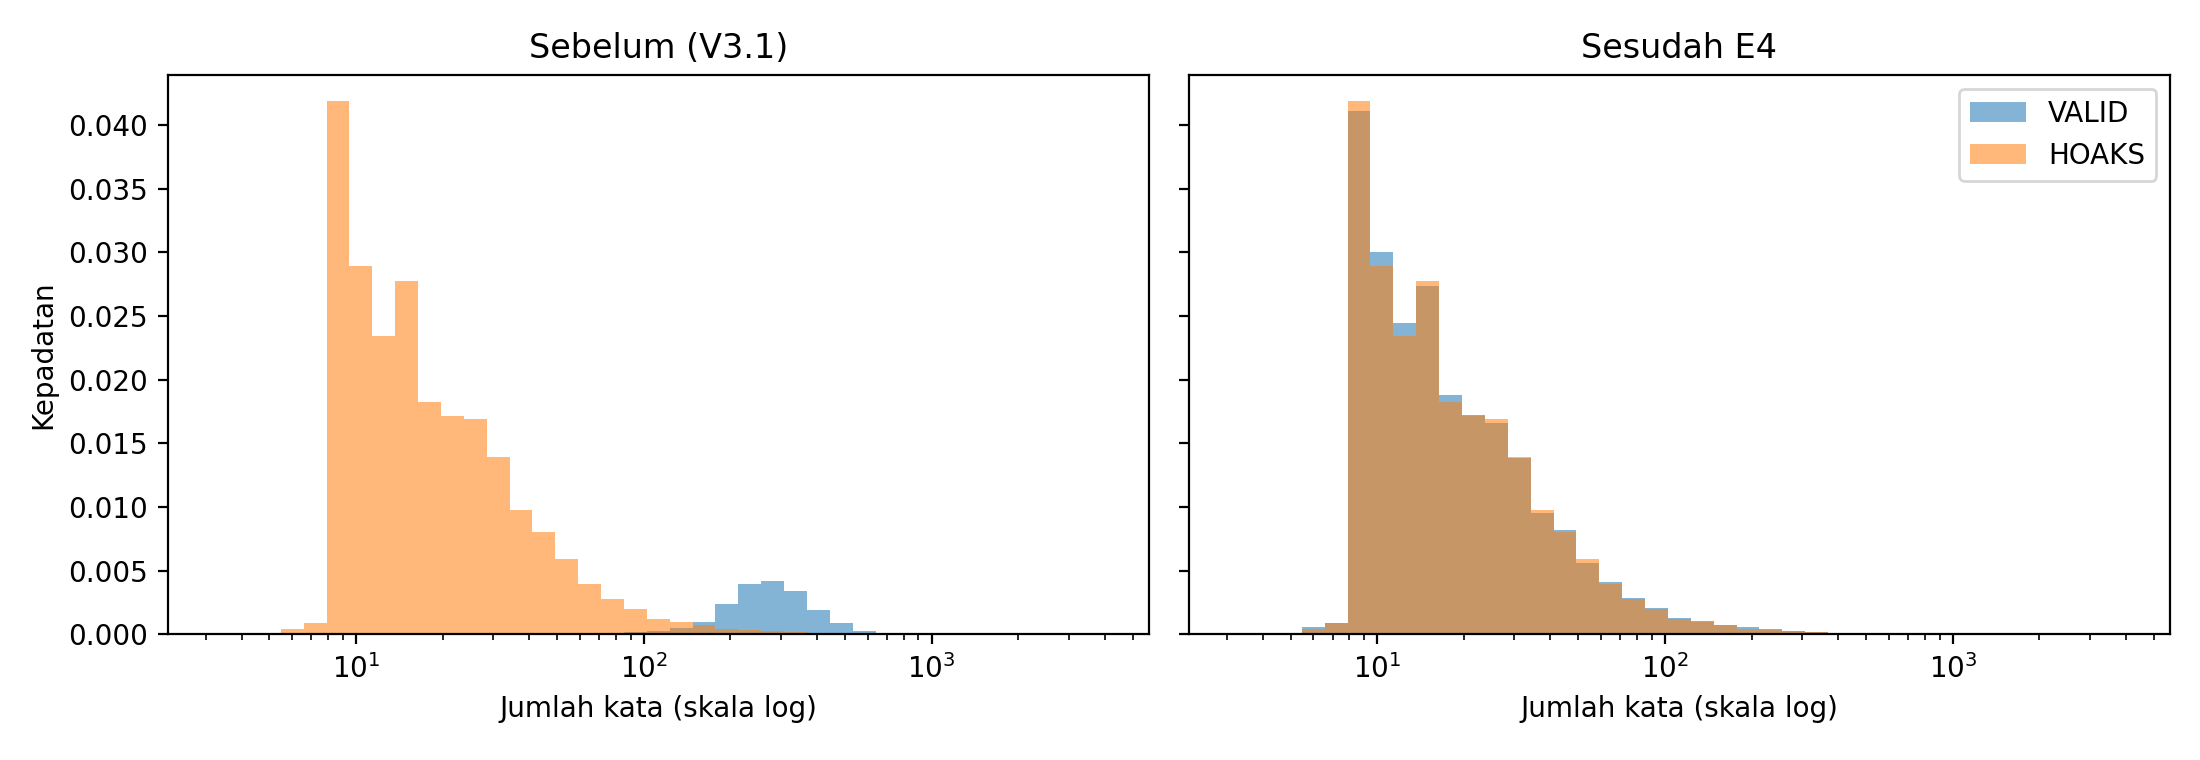

In [7]:
import pandas as pd
from IPython.display import display, Image
pd.set_option("display.precision", 4)
m = pd.read_csv("HASIL_E4/E4_METRIK_VALIDASI.csv")
display(m[["experiment", "model", "condition", "macro_f1", "macro_f1_ci95_low", "macro_f1_ci95_high", "valid_recall", "hoaks_recall"]])
display(pd.read_csv("HASIL_E4/E4_RINGKASAN_SELISIH.csv"))
display(pd.read_csv("HASIL_E4/E4_STATISTIK_PANJANG.csv"))
display(Image("HASIL_E4/E4_DISTRIBUSI_PANJANG.png"))

In [8]:
f = pd.read_csv("HASIL_E4/E4_FITUR_SVM_TERATAS.csv")
display(f[f["rank"] <= 15].pivot_table(index="rank", columns=["condition", "arah"], values="fitur", aggfunc="first"))

condition             e4                        normal            
arah               HOAKS          VALID          HOAKS       VALID
rank                                                              
1                   foto        politik      referensi     politik
2                  video            dpr             yg        kata
3                     yg           soal         sumber         itu
4                 gambar         partai     penjelasan       dalam
5                   akun          ketua           foto        2022
6                 sumber         pemilu         narasi        juga
7                artikel         komisi           hoax          ia
8               facebook  presiden joko           anda        yang
9                    pki        menteri       facebook         dia
10             referensi         parpol        artikel        ujar
11                narasi       gerindra            pki      partai
12         akun facebook         capres           akun        pada
13              whatsapp           atau         gambar  mengatakan
14                  ahok            ppp  akun facebook    tersebut
15               sendiri         nasdem    tidak benar         dan

## 4. Simpan hasil
- `HASIL_E4_VALIDASI.zip` berisi semua file hasil kecuali teks E4. Isinya disalin ke `results/anggota_a/` di repo.
- `E4_TEKS_KONTROL_PANJANG.csv` (±14 MB) disalin ke folder dataset di Google Drive, tidak dimasukkan ke repo.

In [9]:
import shutil
from pathlib import Path
paket = Path("HASIL_E4_REPO"); paket.mkdir(exist_ok=True)
for p in Path("HASIL_E4").glob("E4_*"):
    if p.name != "E4_TEKS_KONTROL_PANJANG.csv":
        shutil.copy(p, paket / p.name)
out = shutil.make_archive("HASIL_E4_VALIDASI", "zip", paket)
print("File ZIP:", out)
try:
    shutil.copy("HASIL_E4/E4_TEKS_KONTROL_PANJANG.csv", Path(DATASET_PATH).parent / "E4_TEKS_KONTROL_PANJANG.csv")
    print("Teks E4 disalin ke folder Drive dataset.")
except Exception as e:
    print("Teks E4 tidak disalin ke Drive:", e)
try:
    from google.colab import files
    files.download(out)
except ImportError:
    pass

File ZIP: /content/HASIL_E4_VALIDASI.zip
Teks E4 tidak disalin ke Drive: [Errno 30] Read-only file system: '/content/drive/MyDrive/Kelompok 5 - PSP/E4_TEKS_KONTROL_PANJANG.csv'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Cara membaca hasil
- **E4_STATISTIK_PANJANG.csv**: median VALID sesudah E4 harus sama dengan median HOAKS.
- **E4_CEK_DESAIN** (LogReg jumlah kata): tinggi pada `normal`, mendekati 0,5 pada `e4`. Ini bukti petunjuk panjang sudah hilang.
- **normal vs e4**: selisih positif dan signifikan berarti model memakai panjang sebagai *shortcut*.
- **silang**: skor turun tajam berarti model yang dilatih teks utuh salah menilai teks pendek. Ini relevan untuk aplikasi.
- **E4_FITUR_SVM_TERATAS.csv**: petunjuk yang tersisa setelah panjang disamakan (topik dan gaya bahasa).